| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../18_HPC_COMPUTACION_CIENTIFICA/18_4_Scientific_computing.ipynb) | [⏩](../20_INVESTIGACION/20_1_papers.ipynb) |

# 19.1 SOFTWARE CIENTÍFICO

El software científico transforma una hipótesis en un experimento que otra persona puede revisar y repetir. Un buen programa deja claras entradas, unidades, supuestos, algoritmos y resultados. Además, debe ayudar a detectar errores antes de convertirlos en una conclusión científica.

Vamos a construir una pequeña biblioteca en memoria para crecimiento logístico, verificarla con una solución exacta y guardar un resultado en un directorio temporal. No se modificarán archivos del proyecto ni datos originales durante las demostraciones.

**Objetivos.** Separar modelo y solver, validar entradas, comprobar propiedades físicas, registrar configuración y producir gráficos que expliquen los resultados. Bibliotecas: NumPy, Matplotlib y biblioteca estándar. Requisitos: ODE, Python y errores numéricos.

## 1. Un problema reproducible

La ecuación logística es
$$u'=r u(1-u/K),\qquad u(0)=u_0,$$
con $r>0$, capacidad $K>0$ y $0<u_0<K$. Su solución exacta es
$$u(t)=\frac{K}{1+(K/u_0-1)e^{-rt}}.$$
Representa un mecanismo idealizado de crecimiento con saturación. Su interpretación real requiere revisar si $r$ y $K$ son constantes y si los datos respaldan ese mecanismo. Aquí nos interesa construir y verificar su implementación.

Usaremos tiempo adimensional. En una aplicación con días, $r$ tendría unidades de día inverso y $K$ las de la población o concentración.

## 2. Separar responsabilidades

El **modelo** calcula $f(t,u;\theta)$, el **solver** decide cómo avanzar en tiempo y el **experimento** elige parámetros, produce métricas y gráficos. Mezclar todo en una función larga dificulta sustituir un método o detectar qué parte causó un error.

La configuración será una dataclass inmutable. Validar una vez evita cálculos silenciosos con una tasa negativa o una capacidad cero. La función de solución exacta se mantendrá separada del solver para que pueda servir como referencia: si ambos reutilizan el mismo algoritmo equivocado, la comparación no detectaría el fallo.

In [1]:
from dataclasses import dataclass, asdict
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tempfile import TemporaryDirectory
import json, hashlib, platform
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})

@dataclass(frozen=True)
class Configuracion:
    tasa: float = 1.2
    capacidad: float = 2.0
    inicial: float = 0.15
    final: float = 5.0
    pasos: int = 100

    def __post_init__(self):
        valores = [self.tasa, self.capacidad, self.inicial, self.final]
        if not np.all(np.isfinite(valores)):
            raise ValueError("Los parámetros deben ser finitos")
        if self.tasa <= 0 or self.capacidad <= 0 or self.final <= 0:
            raise ValueError("Tasa, capacidad y tiempo final deben ser positivos")
        if not 0 < self.inicial < self.capacidad:
            raise ValueError("Este experimento requiere 0 < inicial < capacidad")
        if isinstance(self.pasos, bool) or not isinstance(self.pasos, (int, np.integer)) or self.pasos < 1:
            raise ValueError("pasos debe ser un entero positivo")

cfg = Configuracion()
print(asdict(cfg))

{'tasa': 1.2, 'capacidad': 2.0, 'inicial': 0.15, 'final': 5.0, 'pasos': 100}


## 3. Implementar un solver explícito con contrato claro

RK4 clásico usa cuatro pendientes:
$$k_1=f(t,u),\quad k_2=f(t+h/2,u+hk_1/2),\quad k_3=f(t+h/2,u+hk_2/2),\quad k_4=f(t+h,u+hk_3),$$
$$u_{n+1}=u_n+\frac h6(k_1+2k_2+2k_3+k_4).$$
La función devuelve tiempo y estado, ambos con $N+1$ entradas. La inicial se incluye y el tiempo final se alcanza exactamente mediante `linspace`. Verificaremos finitud después de cada paso para detener el experimento cuando se produce un fallo numérico.

La comprobación de finitud no garantiza precisión ni estabilidad; esas preguntas necesitan pruebas de convergencia y comparación física.

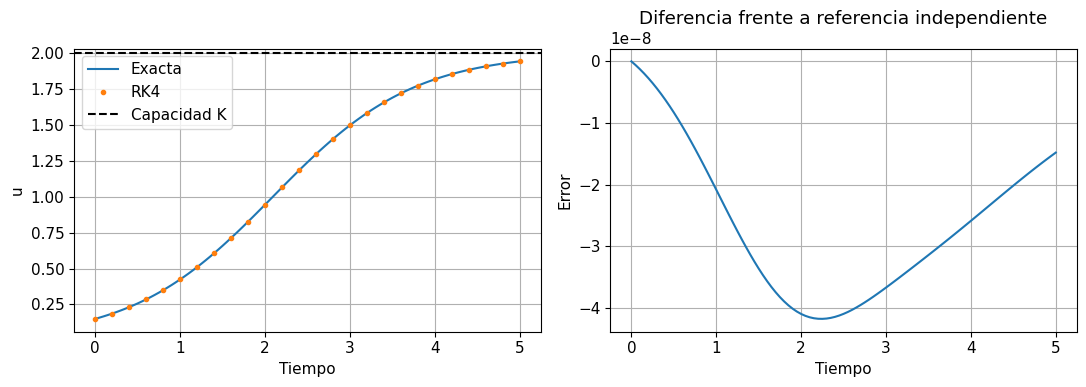

In [2]:
def rhs_logistico(t, u, config):
    return config.tasa*u*(1-u/config.capacidad)

def exacta(t, config):
    factor = config.capacidad/config.inicial-1
    return config.capacidad/(1+factor*np.exp(-config.tasa*np.asarray(t)))

def resolver(config):
    t = np.linspace(0, config.final, config.pasos+1)
    u = np.empty_like(t); u[0] = config.inicial
    h = config.final/config.pasos
    for n in range(config.pasos):
        k1 = rhs_logistico(t[n], u[n], config)
        k2 = rhs_logistico(t[n]+h/2, u[n]+h*k1/2, config)
        k3 = rhs_logistico(t[n]+h/2, u[n]+h*k2/2, config)
        k4 = rhs_logistico(t[n]+h, u[n]+h*k3, config)
        u[n+1] = u[n]+h*(k1+2*k2+2*k3+k4)/6
        if not np.isfinite(u[n+1]):
            raise FloatingPointError(f"Estado no finito en paso {n+1}")
    return t, u

t, u = resolver(cfg)
error = u-exacta(t, cfg)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, exacta(t, cfg), label="Exacta")
axes[0].plot(t[::4], u[::4], "o", ms=3, label="RK4")
axes[0].axhline(cfg.capacidad, color="k", ls="--", label="Capacidad K")
axes[0].set(xlabel="Tiempo", ylabel="u"); axes[0].legend()
axes[1].plot(t, error)
axes[1].set(xlabel="Tiempo", ylabel="Error", title="Diferencia frente a referencia independiente")
plt.tight_layout(); plt.show()

## 4. Pruebas que verifican significado científico

Hay varios niveles. Una prueba de unidad comprueba una función pequeña, por ejemplo que $f(t,K)=0$. Una prueba de integración comprueba que solver y modelo funcionan juntos. Una prueba numérica verifica convergencia y error; una propiedad física comprueba que la solución permanece en el rango esperado para pasos suficientemente pequeños.

No tiene valor científico verificar únicamente que una función devuelve lo mismo que otra copia de su implementación. Elegiremos soluciones exactas, equilibrios y orden esperado. Las tolerancias deben responder a escala y método; `==` entre números flotantes no suele expresar ese objetivo.

In [3]:
assert rhs_logistico(0, cfg.capacidad, cfg) == 0.0
assert rhs_logistico(0, 0.0, cfg) == 0.0
assert t.shape == u.shape == (cfg.pasos+1,)
assert t[0] == 0 and np.isclose(t[-1], cfg.final)
assert np.isclose(u[0], cfg.inicial)
assert np.all(u > 0) and np.all(u < cfg.capacidad)
assert np.all(np.diff(u) >= -1e-12)
assert np.max(np.abs(error)) < 1e-5
print("Equilibrios, forma, condición inicial, rango y precisión verificados.")
# Un fallo esperado debe explicarse y atraparse: no interrumpe el cuaderno.
try:
    Configuracion(capacidad=0)
except ValueError as exc:
    print("Entrada rechazada correctamente:", exc)
else:
    raise AssertionError("No se rechazó capacidad inválida")

Equilibrios, forma, condición inicial, rango y precisión verificados.
Entrada rechazada correctamente: Tasa, capacidad y tiempo final deben ser positivos


## 5. Convergencia y pruebas de regresión numérica

Para este problema suave esperamos $E(h)=C h^4+o(h^4)$. Una prueba de orden es más informativa que fijar una salida de miles de decimales: detecta cambios que alteran el esquema, pero tolera pequeñas diferencias de plataforma.

Una regresión numérica puede guardar métricas de referencia de un experimento; si cambian, hay que investigar si se corrigió un error o se introdujo uno. Actualizar automáticamente las referencias para que todo pase elimina la utilidad de la prueba.

Mediremos error máximo en toda la trayectoria, no solamente en un tiempo donde podrían cancelarse errores.

Órdenes observados: [3.8957964  3.94748209 3.97365979 3.98669972]


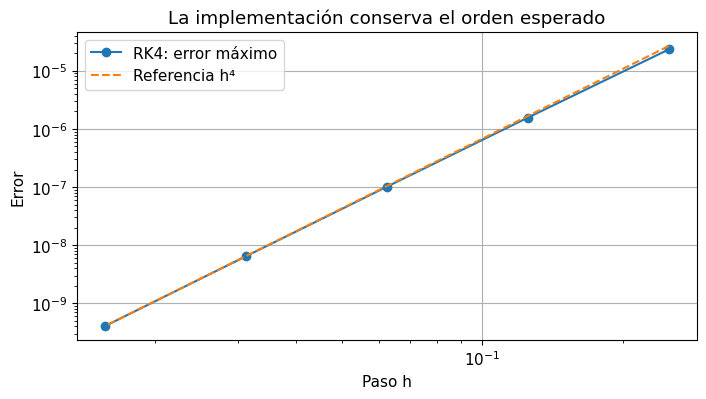

In [4]:
Ns = np.array([20, 40, 80, 160, 320])
errs = []
for n in Ns:
    conf = Configuracion(pasos=int(n))
    tt, uu = resolver(conf)
    errs.append(np.max(np.abs(uu-exacta(tt, conf))))
errs = np.array(errs)
ordenes = np.log(errs[:-1]/errs[1:])/np.log(2)
print("Órdenes observados:", ordenes)
assert np.all(ordenes[-2:] > 3.8)
fig, ax = plt.subplots()
hs = cfg.final/Ns
ax.loglog(hs, errs, "o-", label="RK4: error máximo")
ax.loglog(hs, errs[-1]*(hs/hs[-1])**4, "--", label="Referencia h⁴")
ax.set(xlabel="Paso h", ylabel="Error", title="La implementación conserva el orden esperado")
ax.legend(); plt.show()

## 6. Una propiedad física puede fallar por el método

El modelo logístico conserva $0<u<K$ para la condición inicial elegida, pero un método explícito con paso grande puede sobrepasar el rango. Eso no significa que el software haya cambiado la ecuación: significa que su discretización no representa bien la propiedad en ese régimen.

La curva siguiente contrasta Euler con un paso fino y uno demasiado grande. No aplicaremos recortes como `clip(u,0,K)` para ocultar el problema: un recorte cambia el método y puede sesgar masa o parámetros estimados. Si una aplicación requiere positividad, hay que escoger o diseñar un esquema que la conserve bajo condiciones explícitas.

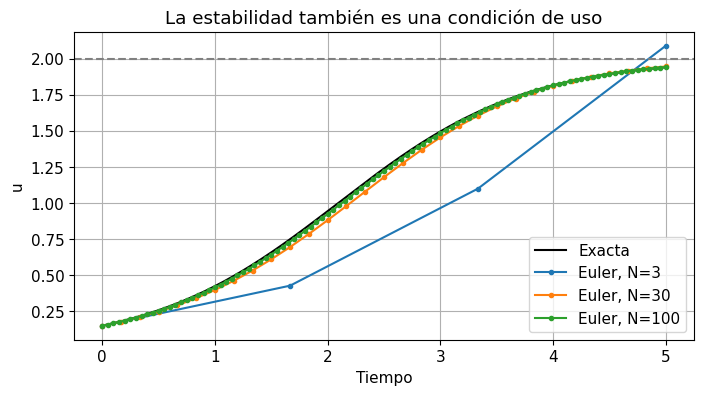

In [5]:
def euler_logistico(config):
    tt = np.linspace(0, config.final, config.pasos+1)
    uu = np.empty_like(tt); uu[0] = config.inicial
    h = config.final/config.pasos
    for i in range(config.pasos):
        uu[i+1] = uu[i]+h*rhs_logistico(tt[i], uu[i], config)
    return tt, uu

fig, ax = plt.subplots()
td = np.linspace(0, cfg.final, 500)
ax.plot(td, exacta(td, cfg), "k", label="Exacta")
for n in [3, 30, 100]:
    cc = Configuracion(pasos=n); te, ue = euler_logistico(cc)
    ax.plot(te, ue, "o-", ms=3, label=f"Euler, N={n}")
ax.axhline(cfg.capacidad, ls="--", color="gray")
ax.set(xlabel="Tiempo", ylabel="u", title="La estabilidad también es una condición de uso")
ax.legend(); plt.show()

## 7. Configuración, metadatos y trazabilidad

Un resultado debería conservar parámetros, unidades, semilla si hay aleatoriedad, versión del código y entorno. El hash de una configuración normalizada ayuda a identificarla, aunque **no sustituye** el hash del código ni garantiza autenticidad científica.

Registraremos versión de Python y NumPy, método y parámetros. En un proyecto formal se añadirían commit de Git, archivo de dependencias y procedencia de datos. Los archivos de configuración deben evitar secretos y rutas privadas innecesarias.

In [6]:
config_json = json.dumps(asdict(cfg), sort_keys=True, separators=(",", ":"))
id_config = hashlib.sha256(config_json.encode("utf-8")).hexdigest()[:12]
registro = {
    "id_config": id_config, "configuracion": asdict(cfg),
    "modelo": "logistico adimensional", "solver": "RK4 clásico",
    "python": platform.python_version(), "numpy": np.__version__,
    "error_maximo": float(np.max(np.abs(error)))
}
print(json.dumps(registro, indent=2, ensure_ascii=False))
# Ejemplo aislado de almacenamiento: el directorio temporal se elimina al finalizar.
with TemporaryDirectory(prefix="sciml_resultado_") as carpeta:
    ruta = Path(carpeta)/"experimento.json"
    ruta.write_text(json.dumps(registro, ensure_ascii=False, indent=2), encoding="utf-8")
    recuperado = json.loads(ruta.read_text(encoding="utf-8"))
    assert recuperado["id_config"] == id_config
    print("Resultado escrito y leído en almacenamiento temporal.")

{
  "id_config": "3a7e7c1d4cd9",
  "configuracion": {
    "tasa": 1.2,
    "capacidad": 2.0,
    "inicial": 0.15,
    "final": 5.0,
    "pasos": 100
  },
  "modelo": "logistico adimensional",
  "solver": "RK4 clásico",
  "python": "3.10.12",
  "numpy": "2.2.6",
  "error_maximo": 4.1727135746683075e-08
}
Resultado escrito y leído en almacenamiento temporal.


## 8. Estado oculto de Jupyter

Una celda puede funcionar porque utiliza una variable creada horas antes y ausente al reiniciar. La prueba práctica es reiniciar el kernel y ejecutar todo en orden. Las funciones deberían recibir sus entradas como argumentos en lugar de depender de muchas variables globales.

El cuaderno está organizado para esa ejecución secuencial. La semilla, cuando se use, pertenece al experimento y se pasa al generador. No se modifican archivos de datos originales ni se requieren celdas ocultas. En un proyecto grande, extraer solver y modelos a módulos importables facilita pruebas y revisión.

## 9. Aleatoriedad controlada y experimentos repetidos

En SciML, ruido de sensores, inicialización de redes y muestreo de puntos de colocación afectan resultados. Una semilla facilita repetir una realización; varias semillas ayudan a medir variabilidad. No hay que seleccionar solo la que ofrece el resultado más favorable.

Generaremos observaciones logísticas ruidosas, con semillas explícitas y arrays independientes. La figura muestra que un mismo modelo puede producir datos distintos sin que el solver sea incorrecto.

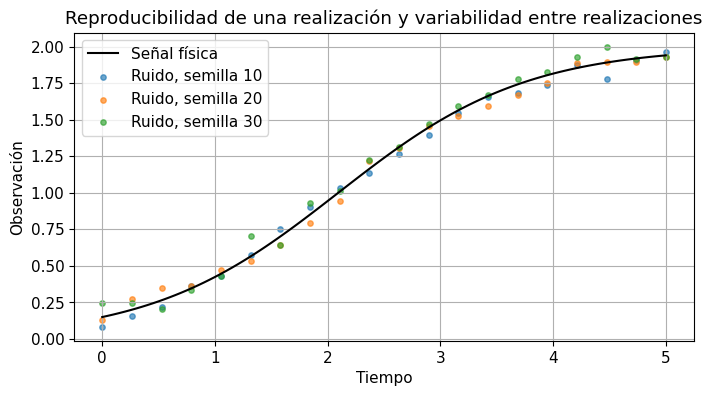

In [7]:
t_sensor = np.linspace(0, cfg.final, 20)
fig, ax = plt.subplots()
ax.plot(t, exacta(t, cfg), "k", label="Señal física")
for seed in [10, 20, 30]:
    rr = np.random.default_rng(seed)
    yy = exacta(t_sensor, cfg)+rr.normal(0, 0.06, len(t_sensor))
    ax.scatter(t_sensor, yy, s=15, alpha=0.65, label=f"Ruido, semilla {seed}")
ax.set(xlabel="Tiempo", ylabel="Observación", title="Reproducibilidad de una realización y variabilidad entre realizaciones")
ax.legend(); plt.show()

## 10. Organización de un proyecto

Una estructura posible separa `src/` para código, `tests/` para pruebas, `notebooks/` para exploración, `configs/` para entradas y `results/` para artefactos derivados. Los datos originales deben tener procedencia documentada y conservarse aparte. No existe una única estructura obligatoria: importa que otra persona encuentre qué ejecutar y qué resultado esperar.

Versiona código y configuraciones con Git; para datos o modelos grandes, utiliza almacenamiento y versiones adecuados. Un cambio debería describir el problema, el comportamiento nuevo y las comprobaciones realizadas. Archivos generados no deben ocultar qué parámetros los produjeron.

## 11. Entorno y dependencia mínima

Documenta bibliotecas y versiones que afectan el experimento. Un entorno virtual evita mezclar dependencias de proyectos, y un archivo de requisitos ayuda a reconstruirlo. Fijar versiones puede mejorar repetición, pero también requiere revisar actualizaciones: reproducibilidad no consiste en ignorar correcciones para siempre.

No instales paquetes desde celdas sin explicar el entorno; el usuario debe poder ejecutar la parte matemática sin modificar su sistema inadvertidamente. Estas demostraciones usan dependencias declaradas y la biblioteca estándar para almacenamiento temporal.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../18_HPC_COMPUTACION_CIENTIFICA/18_4_Scientific_computing.ipynb) | [⏩](../20_INVESTIGACION/20_1_papers.ipynb) |